In [7]:
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.time import Time
import numpy as np
import matplotlib.pyplot as plt

In [8]:
# Step 1: Create Time objects for our epochs
epoch_2000 = Time('J2000')  # Julian year 2000.0
epoch_2025 = Time('J2025')  # Julian year 2025.0

print(f"Starting epoch: {epoch_2000.iso} (J{epoch_2000.jyear})")
print(f"Target epoch:   {epoch_2025.iso} (J{epoch_2025.jyear})")

# Calculate time difference
dt = (epoch_2025 - epoch_2000).to(u.yr)
print(f"Time difference: {dt}")
print()

Starting epoch: 2000-01-01 12:00:00.000 (J2000.0)
Target epoch:   2024-12-31 18:00:00.000 (J2025.0)
Time difference: 25.0 yr



In [9]:
# Step 2: Create the initial SkyCoord object with proper motion
barnards_2000 = SkyCoord(
    ra=269.45207*u.degree, 
    dec=4.69339*u.degree,
    pm_ra_cosdec=-798.71*u.mas/u.yr,  # from SIMBAD
    pm_dec=10337.77*u.mas/u.yr,       # from SIMBAD
    obstime=epoch_2000,
    frame='icrs'
)

print("Barnard's Star at epoch J2000.0 (SkyCoord object):")
print(f"RA:  {barnards_2000.ra.to_string(unit=u.hour, precision=2)}")
print(f"Dec: {barnards_2000.dec.to_string(unit=u.degree, precision=2)}")
print(f"Proper motion (RA*cos(dec)): {barnards_2000.pm_ra_cosdec}")
print(f"Proper motion (Dec): {barnards_2000.pm_dec}")
print()



Barnard's Star at epoch J2000.0 (SkyCoord object):
RA:  17h57m48.50s
Dec: 4d41m36.20s
Proper motion (RA*cos(dec)): -798.7100000000002 mas / yr
Proper motion (Dec): 10337.77 mas / yr



In [10]:
# Step 3: Propagate the position to a different epoch

#extract values at J2000.0
ra_2000 = barnards_2000.ra
dec_2000 = barnards_2000.dec
pm_ra_cosdec = barnards_2000.pm_ra_cosdec
pm_dec = barnards_2000.pm_dec

#Manually calculate the position change, dividing pmra by cos(dec)
delta_ra = pm_ra_cosdec * dt / np.cos(dec_2000.deg*np.pi/180)
delta_dec = pm_dec * dt

# Apply the changes to get new position
ra_2025 = ra_2000 + delta_ra
dec_2025 = dec_2000 + delta_dec

#Create new SkyCoord object for the propagated position
barnards_2025_manual = SkyCoord(
    ra=ra_2025, 
    dec=dec_2025, 
    frame='icrs',
    obstime=epoch_2025
)

#Calculate total angular motion
total_motion = np.sqrt(delta_ra**2 + delta_dec**2)
#print(f"Total angular motion: {total_motion.to(u.arcsec):.2f} = {total_motion.to(u.arcmin):.3f}")
print('Total angular motion: {0:.2f} = {1:.2f}'.format(total_motion.to(u.arcsec),total_motion.to(u.arcmin)))
print()

Total angular motion: 259.22 arcsec = 4.32 arcmin



In [13]:
#Verify against apply_space_motion() method
barnards_2025_builtin = barnards_2000.apply_space_motion(epoch_2025)
diff_ra = (barnards_2025_manual.ra - barnards_2025_builtin.ra).to(u.mas)
diff_dec = (barnards_2025_manual.dec - barnards_2025_builtin.dec).to(u.mas)
#differences
print('the differences are tiny: {0:.3f} {1:.3f}'.format(diff_ra,diff_dec))

the differences are tiny: 2.061 mas 0.216 mas


In [31]:
#LONG TERM MOTION
years = np.linspace(1950, 2050, 101)
times = Time(years, format='jyear')

dts=(times-barnards_2000.obstime).to(u.yr)

ras_manual = barnards_2000.ra + barnards_2000.pm_ra_cosdec * dts / np.cos(barnards_2000.dec)
decs_manual = barnards_2000.dec + barnards_2000.pm_dec * dts




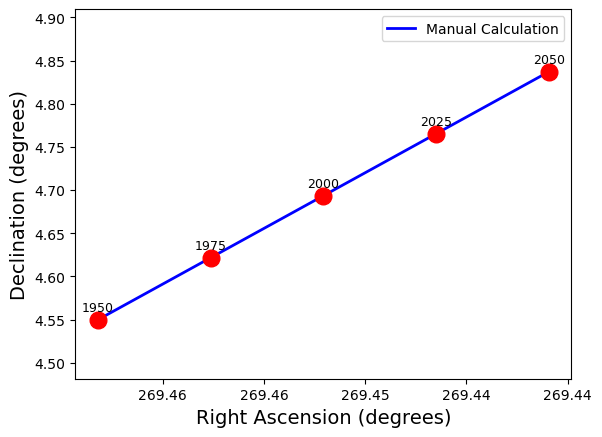

In [50]:
#plotting

from matplotlib.ticker import FormatStrFormatter

fig,ax=plt.subplots()

ax.plot(ras_manual.degree, decs_manual.degree, 'b-', linewidth=2, 
         label="Manual Calculation")
marker_years = [1950, 1975, 2000, 2025, 2050]

for year in marker_years:
    dt_marker = (Time(year, format='jyear') - barnards_2000.obstime).to(u.yr)
    ra_marker = barnards_2000.ra + barnards_2000.pm_ra_cosdec * dt_marker / np.cos(barnards_2000.dec)
    dec_marker = barnards_2000.dec + barnards_2000.pm_dec * dt_marker
    ax.plot(ra_marker.degree, dec_marker.degree, 'o', color='red',markersize=12)
    ax.text(ra_marker.degree, dec_marker.degree + 0.01, f'{year}', 
             ha='center', fontsize=9)

ax.set_xlabel('Right Ascension (degrees)',fontsize=14)
ax.set_ylabel('Declination (degrees)',fontsize=14)
ax.set_ylim(np.min(decs_manual.degree)*0.985,1.015*np.max(decs_manual.degree))
ax.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))
ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

ax.legend()
ax.invert_xaxis()